### REFERENCES
 * Nampiasa chagpt

# Problem framing

> ## Main goal
 > Predict whether a client will default on a loan at application time, in order to support credit risk decision-making.

> ## Value
 > * Reduce financial risk
 > * Improve loan approval decisions
 > * Optimize interest rate strategies
 > * Increase portfolio profitability
 > * Make decisions more consistent and scalable
> 
> Even a small improvement in default prediction can significantly reduce expected credit losses at portfolio level.

> ## Can we solve it without ML?
> We could use simple rules, but ML allows:
> 
> * capturing complex feature interactions
> * modeling nonlinear relationships
> * adapting to data patterns automatically
> * improving predictive performance


> ## Do we have enough quality data?
> We must verify:
> * No corrupted values
> * Valid ranges (income > 0, interest rate between 0–100)
> * Sufficient variability across loan intents and grades

> The dataset contains tens of thousands of labeled loans, which is sufficient for supervised learning.
>
> Potentially strong predictors include:
> * loan percent income
> * loan grade
> * loan int rate
> * person income
> * ...

> ## Technical formulation
> 
> The model must estimate the probability of default given customer features.
> This is a:
> 
> * Supervised learning problem
> * Binary classification
> * Probabilistic prediction task

> The target indicates whether a loan is successfully repaid (1) or defaulted (0). A model is considered successful if it can accurately predict the loan outcomes. This can be measured in several complementary ways:
> * Achieving a strong ROC-AUC, meaning the model correctly ranks defaulters above non-defaulters.
> * Improving the F1-score for the default class, ensuring a good balance between precision and recall.
> * Accuracy can also be reported, but it is secondary and may be misleading in the presence of class imbalance.


> **Non-ML Baselines:**
> 
> Simple baselines include predicting the majority class, predicting randomly, or using simple rules based on features like income or credit history.
> 
> The ML model must outperform these baselines both statistically and financially.

> ### What are the Input and Output?
> Input (X):
> 
> Each row represents a borrower.
> Features include:
> 
> * person_age
> * person_income
> * person_emp_length
> * loan_amnt
> * loan_int_rate
> * loan_percent_income
> * cb_person_cred_hist_length
> * person_home_ownership
> * loan_intent
> * loan_grade
> * cb_person_default_on_file
>
> Output (y):
> 
> Binary label (loan_status):
> 
> * 0 → No default
> * 1 → Default

# Data collection

> ## Dataset size and sampling strategy
> The original train.csv dataset will be split into training and validation sets. We use 80% of the data for training and 20% for validation, ensuring the split is random but reproducible by setting a random seed. This helps evaluate model performance on unseen data before testing on test.csv.

In [27]:
import numpy as np
import pandas as pd
import seaborn as sns

In [28]:
train_df = pd.read_csv("train.csv")
test_df = pd.read_csv("test.csv")

> ## Data features and label

In [29]:
train_df.keys().to_list()

['id',
 'person_age',
 'person_income',
 'person_home_ownership',
 'person_emp_length',
 'loan_intent',
 'loan_grade',
 'loan_amnt',
 'loan_int_rate',
 'loan_percent_income',
 'cb_person_default_on_file',
 'cb_person_cred_hist_length',
 'loan_status']

In [30]:
print(f"Types: {train_df.dtypes}") # features types

Types: id                              int64
person_age                      int64
person_income                   int64
person_home_ownership          object
person_emp_length             float64
loan_intent                    object
loan_grade                     object
loan_amnt                       int64
loan_int_rate                 float64
loan_percent_income           float64
cb_person_default_on_file      object
cb_person_cred_hist_length      int64
loan_status                     int64
dtype: object


> ## Data quality verification

In [31]:
train_df.describe()

,id,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,loan_status
count,58645.000000,58645.000000,5.864500e+04,58645.000000,58645.000000,58645.000000,58645.000000,58645.000000,58645.000000
mean,29322.000000,27.550857,6.404617e+04,4.701015,9217.556518,10.677874,0.159238,5.813556,0.142382
std,16929.497605,6.033216,3.793111e+04,3.959784,5563.807384,3.034697,0.091692,4.029196,0.349445
min,0.000000,20.000000,4.200000e+03,0.000000,500.000000,5.420000,0.000000,2.000000,0.000000
25%,14661.000000,23.000000,4.200000e+04,2.000000,5000.000000,7.880000,0.090000,3.000000,0.000000
50%,29322.000000,26.000000,5.800000e+04,4.000000,8000.000000,10.750000,0.140000,4.000000,0.000000
75%,43983.000000,30.000000,7.560000e+04,7.000000,12000.000000,12.990000,0.210000,8.000000,0.000000
max,58644.000000,123.000000,1.900000e+06,123.000000,35000.000000,23.220000,0.830000,30.000000,1.000000


In [32]:
test_df.describe()

,id,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length
count,39098.000000,39098.000000,3.909800e+04,39098.000000,39098.000000,39098.000000,39098.000000,39098.000000
mean,78193.500000,27.566781,6.406046e+04,4.687068,9251.466188,10.661216,0.159573,5.830707
std,11286.764749,6.032761,3.795583e+04,3.868395,5576.254680,3.020220,0.091633,4.072157
min,58645.000000,20.000000,4.000000e+03,0.000000,700.000000,5.420000,0.000000,2.000000
25%,68419.250000,23.000000,4.200000e+04,2.000000,5000.000000,7.880000,0.090000,3.000000
50%,78193.500000,26.000000,5.800000e+04,4.000000,8000.000000,10.750000,0.140000,4.000000
75%,87967.750000,30.000000,7.588500e+04,7.000000,12000.000000,12.990000,0.210000,8.000000
max,97742.000000,94.000000,1.900000e+06,42.000000,35000.000000,22.110000,0.730000,30.000000


In [33]:
print(f"The train dataset size: {len(train_df)}")
print(f"The test dataset size {len(test_df)}")


The train dataset size: 58645
The test dataset size 39098


In [34]:
print(f"Shape train: {train_df.shape}")
print(f"Shape test: {test_df.shape}")
print("\nTrain loan status distribution:\n", train_df['loan_status'].value_counts(normalize=True))

Shape train: (58645, 13)
Shape test: (39098, 12)

Train loan status distribution:
 loan_status
0    0.857618
1    0.142382
Name: proportion, dtype: float64


> ## Split data

In [35]:
from sklearn.model_selection import train_test_split

X = train_df.drop(columns=['loan_status'])
y = train_df['loan_status']

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

X_test = test_df.copy()

print(f"Training set size: {len(X_train)}, Validation set size: {len(X_val)}")

Training set size: 46916, Validation set size: 11729


# Data wrangling

> ## Data transformation pipeline

In [36]:
train_df.isna().sum() # cols containing NAN cell count

id                            0
person_age                    0
person_income                 0
person_home_ownership         0
person_emp_length             0
loan_intent                   0
loan_grade                    0
loan_amnt                     0
loan_int_rate                 0
loan_percent_income           0
cb_person_default_on_file     0
cb_person_cred_hist_length    0
loan_status                   0
dtype: int64

In [37]:
test_df.isna().sum() # cols containing NAN cell count

id                            0
person_age                    0
person_income                 0
person_home_ownership         0
person_emp_length             0
loan_intent                   0
loan_grade                    0
loan_amnt                     0
loan_int_rate                 0
loan_percent_income           0
cb_person_default_on_file     0
cb_person_cred_hist_length    0
dtype: int64

In [38]:
train_df.dtypes

id                              int64
person_age                      int64
person_income                   int64
person_home_ownership          object
person_emp_length             float64
loan_intent                    object
loan_grade                     object
loan_amnt                       int64
loan_int_rate                 float64
loan_percent_income           float64
cb_person_default_on_file      object
cb_person_cred_hist_length      int64
loan_status                     int64
dtype: object

In [39]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

numerical_cols = [
    'person_age','person_income','person_emp_length','loan_amnt',
    'loan_int_rate','loan_percent_income','cb_person_cred_hist_length'
]

categorical_cols = [
    'person_home_ownership','loan_intent','loan_grade','cb_person_default_on_file'
]

def add_features(df):
    df = df.copy()
    # Ratio loan / income
    df['loan_to_income'] = df['loan_amnt'] / df['person_income']
    # Log-transform incomes
    df['log_person_income'] = np.log1p(df['person_income'])
    return df

X_train = add_features(X_train)
X_val = add_features(X_val)
X_test = add_features(X_test)

# Add the new features
numerical_cols += ['loan_to_income','log_person_income']

# Numerical transformer : StandardScaler
# Categorical transformer : OneHotEncoder
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols)
    ]
)

# Pipeline
pipeline = Pipeline(steps=[('preprocessing', preprocessor)])

# Fit sur train
pipeline.fit(X_train)

# Transform train, val et test
X_train = pipeline.transform(X_train)
X_val = pipeline.transform(X_val)
X_test = pipeline.transform(X_test)


# Final shapes
print("X_train shape:", X_train.shape)
print("X_val shape:", X_val.shape)
print("X_test shape:", X_test.shape)

X_train shape: (46916, 28)
X_val shape: (11729, 28)
X_test shape: (39098, 28)


# Data analysis

Income distribution:
count    5.864500e+04
mean     6.404617e+04
std      3.793111e+04
min      4.200000e+03
25%      4.200000e+04
50%      5.800000e+04
75%      7.560000e+04
max      1.900000e+06
Name: person_income, dtype: float64


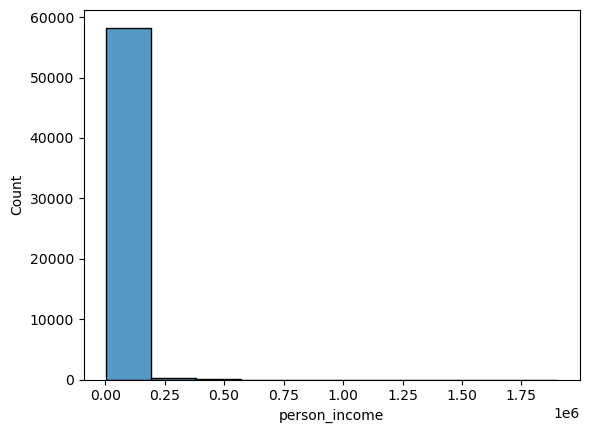

In [40]:
sns.histplot(train_df["person_income"], bins=10)
print("Income distribution:", train_df['person_income'].describe(), sep='\n')

Age distribution:
count    58645.000000
mean        27.550857
std          6.033216
min         20.000000
25%         23.000000
50%         26.000000
75%         30.000000
max        123.000000
Name: person_age, dtype: float64


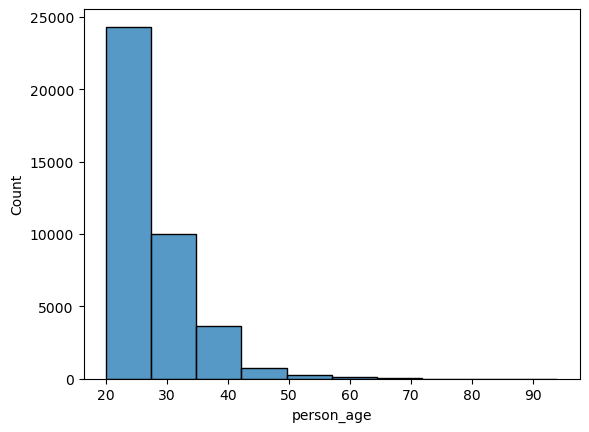

In [18]:
sns.histplot(test_df["person_age"], bins=10)
print("Age distribution:", train_df['person_age'].describe(), sep='\n')

<Axes: xlabel='loan_grade', ylabel='count'>

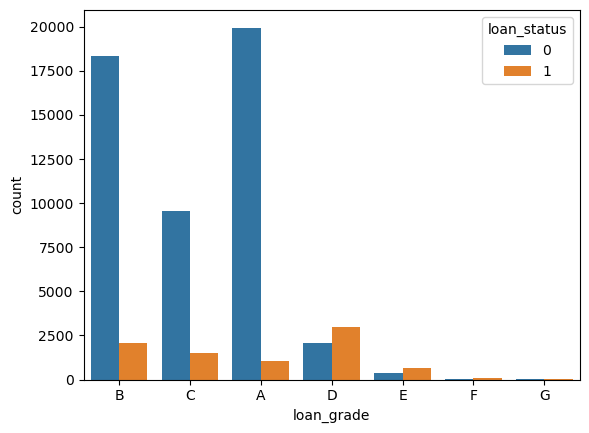

In [167]:
sns.countplot(x='loan_grade', hue='loan_status', data=train_df)

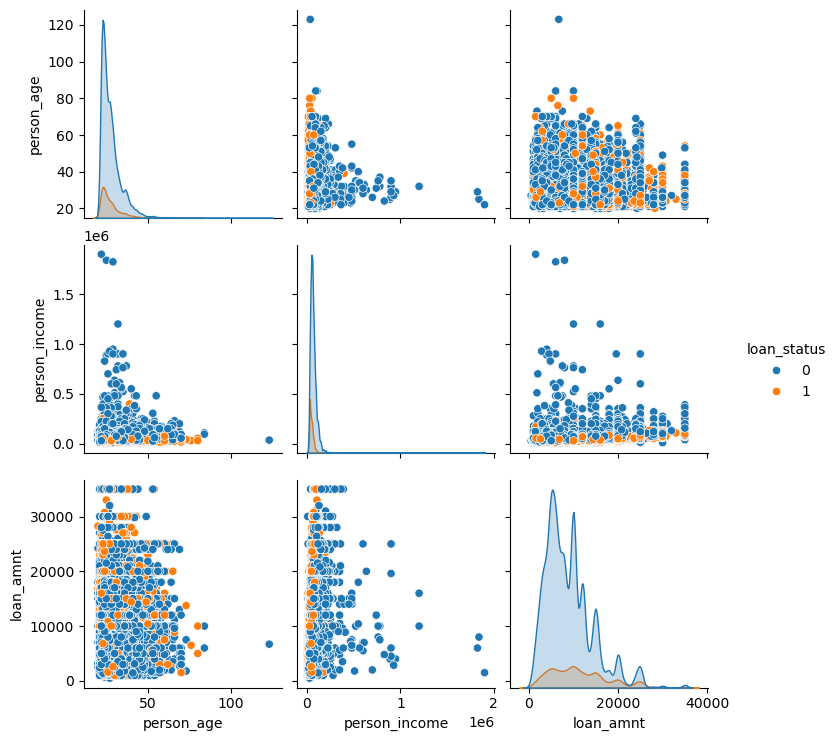

In [139]:
sns.pairplot(train_df, hue='loan_status', vars=['person_age','person_income','loan_amnt'])

<Axes: xlabel='person_income', ylabel='loan_amnt'>

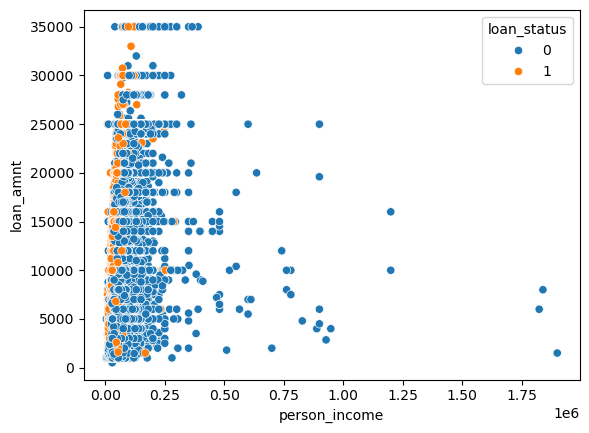

In [168]:
sns.scatterplot(x='person_income', y='loan_amnt', hue='loan_status', data=train_df)

> ## Data after normalization and transformations

In [41]:
print("Mean per feature:", np.mean(X_train, axis=0))
print("Std per feature:", np.std(X_train, axis=0))
print("Min per feature:", np.min(X_train, axis=0))
print("Max per feature:", np.max(X_train, axis=0))

Mean per feature: [ 1.29237121e-16 -2.00961111e-16 -6.71680670e-17  2.86978785e-16
 -1.79274183e-16  1.25843103e-16  2.02511698e-16 -2.38536088e-16
  8.32747726e-16  4.24844403e-01  1.47071362e-03  5.29030608e-02
  5.20781823e-01  1.54318356e-01  2.10205474e-01  1.07085003e-01
  1.87036405e-01  1.69814136e-01  1.71540626e-01  3.58662290e-01
  3.47152357e-01  1.88144769e-01  8.55997954e-02  1.73501577e-02
  2.57907750e-03  5.11552562e-04  8.51223463e-01  1.48776537e-01]
Std per feature: [1.         1.         1.         1.         1.         1.
 1.         1.         1.         0.49431937 0.03832167 0.22383996
 0.49956793 0.36125365 0.40745445 0.30922129 0.38994075 0.37546943
 0.37698069 0.47960781 0.4760647  0.39082773 0.27977218 0.13057232
 0.05071909 0.02261174 0.35586806 0.35586806]
Min per feature: [-1.2503502  -1.66155945 -1.20575842 -1.5659646  -1.72825983 -1.73178172
 -0.94645448 -1.65378302 -5.72363647  0.          0.          0.
  0.          0.          0.          0.        

> ## Clip outliers

In [42]:
for i, col in enumerate(numerical_cols):
    lower = np.percentile(X_train[:, i], 1)
    upper = np.percentile(X_train[:, i], 99)
    X_train[:, i] = np.clip(X_train[:, i], lower, upper)
    X_val[:, i]   = np.clip(X_val[:, i], lower, upper)
    X_test[:, i]  = np.clip(X_test[:, i], lower, upper)

In [43]:
# Results
print("Mean per feature:", np.mean(X_train, axis=0))
print("Std per feature:", np.std(X_train, axis=0))
print("Min per feature:", np.min(X_train, axis=0))
print("Max per feature:", np.max(X_train, axis=0))

Mean per feature: [-1.03984942e-02 -1.93795875e-02 -6.96590322e-03 -6.97781769e-03
 -3.37211970e-03 -3.38476771e-03 -1.40378760e-02 -5.77940729e-03
 -7.17484215e-04  4.24844403e-01  1.47071362e-03  5.29030608e-02
  5.20781823e-01  1.54318356e-01  2.10205474e-01  1.07085003e-01
  1.87036405e-01  1.69814136e-01  1.71540626e-01  3.58662290e-01
  3.47152357e-01  1.88144769e-01  8.55997954e-02  1.73501577e-02
  2.57907750e-03  5.11552562e-04  8.51223463e-01  1.48776537e-01]
Std per feature: [0.95106114 0.82276366 0.97203442 0.97339233 0.99129327 0.98273216
 0.94447824 0.95876089 0.96676243 0.49431937 0.03832167 0.22383996
 0.49956793 0.36125365 0.40745445 0.30922129 0.38994075 0.37546943
 0.37698069 0.47960781 0.4760647  0.39082773 0.27977218 0.13057232
 0.05071909 0.02261174 0.35586806 0.35586806]
Min per feature: [-1.08497536 -1.1773271  -1.20575842 -1.4398811  -1.72825983 -1.40525719
 -0.94645448 -1.42801491 -2.13663802  0.          0.          0.
  0.          0.          0.          0.

In [44]:
# Target verification
unique, counts = np.unique(y_train, return_counts=True)
print("Target distribution:", dict(zip(unique, counts)))

Target distribution: {np.int64(0): np.int64(40236), np.int64(1): np.int64(6680)}


> ## Summary

> The training set contains 58,645 samples (13 features) and the test set contains 39,098 samples (12 features).

> The target variable loan_status is imbalanced, with 85.76% non-defaults (0) and 14.24% defaults (1).

> Borrowers are mostly young (mean age ≈ 27.6, median 26), indicating a strong concentration between 20 and 30 years old. The maximum age (123) suggests a possible outlier.

> Income has a wide distribution (mean ≈ $64,046) with very high maximum values, indicating potential outliers and right skewness.

# Model and Training

In [45]:
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.naive_bayes import GaussianNB, BernoulliNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Models and hyperparams
models_params = {
    "Logistic Binary": {
        "model": LogisticRegression(solver='liblinear', max_iter=1000),
        "params": {"C": [0.01, 0.1, 1, 10], "penalty": ['l2']}
    },
    "Logistic Multinomial": {
        "model": LogisticRegression(multi_class='multinomial', solver='saga', max_iter=1000),
        "params": {"C": [0.01, 0.1, 1, 10], "penalty": ['l2']}
    },
    "Robust Logistic": {
        "model": LogisticRegression(solver='saga', max_iter=1000),
        "params": {"C": [0.01, 0.1, 1, 10], "penalty": ['l1']}
    },
    "Logistic Regression CV": {
        "model": LogisticRegressionCV(cv=5, max_iter=1000, scoring='f1', solver='lbfgs'),
        "params": {}  # déjà automatique
    },
    "Gaussian NB": {"model": GaussianNB(), "params": {}},
    "Bernoulli NB": {"model": BernoulliNB(), "params": {}},
    "LDA (GDA)": {"model": LinearDiscriminantAnalysis(), "params": {"shrinkage": [None, 'auto'], "solver": ['svd', 'lsqr']}},
    "QDA": {"model": QuadraticDiscriminantAnalysis(), "params": {}},
    # "SVM Linear": {"model": SVC(kernel='linear', probability=True), "params": {"C": [0.1, 1, 10]}},
    "Random Forest": {"model": RandomForestClassifier(random_state=42), "params": {"n_estimators": [100,200], "max_depth": [None,10,20]}},
    "Gradient Boosting": {"model": GradientBoostingClassifier(random_state=42), "params": {"n_estimators": [100,200], "max_depth": [3,5]}}
}

# Training
results = []

for name, mp in models_params.items():
    print(f"Training {name}...")
    
    model = mp["model"]
    param_grid = mp["params"]
    
    # GridSearchCV seulement si params à tuner
    if param_grid:
        grid = GridSearchCV(model, param_grid, cv=3, scoring='f1', n_jobs=-1)
        grid.fit(X_train, y_train)
        best_model = grid.best_estimator_
    else:
        model.fit(X_train, y_train)
        best_model = model
    
    # Prédiction sur validation
    y_val_pred = best_model.predict(X_val)
    
    # ROC-AUC
    try:
        y_val_prob = best_model.predict_proba(X_val)[:,1]
        roc_auc = roc_auc_score(y_val, y_val_prob)
    except:
        roc_auc = None
    
    results.append({
        "Model": name,
        "Best_Params": getattr(best_model, "get_params", lambda : None)() if param_grid else None,
        "Accuracy": accuracy_score(y_val, y_val_pred),
        "F1": f1_score(y_val, y_val_pred),
        "ROC-AUC": roc_auc
    })



Training Logistic Binary...
Training Logistic Multinomial...


C:\Users\hp\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1262: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, binary problems will be fit as proper binary  logistic regression models (as if multi_class='ovr' were set). Leave it to its default value to avoid this warning.
  warnings.warn(


Training Robust Logistic...
Training Logistic Regression CV...
Training Gaussian NB...
Training Bernoulli NB...
Training LDA (GDA)...


C:\Users\hp\anaconda3\Lib\site-packages\sklearn\model_selection\_validation.py:516: FitFailedWarning: 
3 fits failed out of a total of 12.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
3 fits failed with the following error:
Traceback (most recent call last):
  File "C:\Users\hp\anaconda3\Lib\site-packages\sklearn\model_selection\_validation.py", line 859, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\hp\anaconda3\Lib\site-packages\sklearn\base.py", line 1365, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "C:\Users\hp\anaconda3\Lib\site-packages\sklearn\discriminant_analysis.py", line 700, in fit
    raise NotImplementedError(

Training QDA...
Training Random Forest...


C:\Users\hp\anaconda3\Lib\site-packages\sklearn\discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 0 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
C:\Users\hp\anaconda3\Lib\site-packages\sklearn\discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 1 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(


Training Gradient Boosting...


Results:
                    Model                                        Best_Params  \
9       Gradient Boosting  {'ccp_alpha': 0.0, 'criterion': 'friedman_mse'...   
8           Random Forest  {'bootstrap': True, 'ccp_alpha': 0.0, 'class_w...   
0         Logistic Binary  {'C': 10, 'class_weight': None, 'dual': False,...   
1    Logistic Multinomial  {'C': 10, 'class_weight': None, 'dual': False,...   
4             Gaussian NB                                               None   
3  Logistic Regression CV                                               None   
2         Robust Logistic  {'C': 1, 'class_weight': None, 'dual': False, ...   
7                     QDA                                               None   
5            Bernoulli NB                                               None   
6               LDA (GDA)  {'covariance_estimator': None, 'n_components':...   

   Accuracy        F1   ROC-AUC  
9  0.951658  0.810937  0.957367  
8  0.950720  0.804598  0.939844  
0  0.912

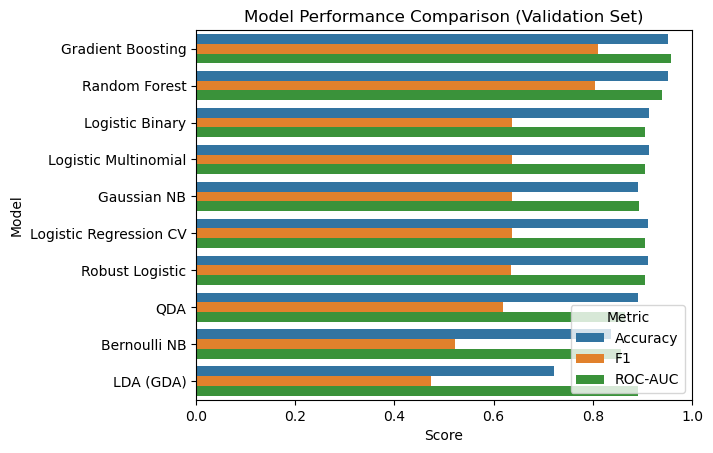

Best model based on F1-score: Gradient Boosting


,loss,'log_loss'
,learning_rate,0.1
,n_estimators,100
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


In [46]:
# Results
results_df = pd.DataFrame(results).sort_values(by='F1', ascending=False)
print("Results:")
print(results_df)

# Graph comparaison
results_melted = results_df.melt(id_vars=["Model"], value_vars=["Accuracy","F1","ROC-AUC"], 
                                 var_name="Metric", value_name="Score")

sns.barplot(x="Score", y="Model", hue="Metric", data=results_melted)
plt.title("Model Performance Comparison (Validation Set)")
plt.xlim(0,1)
plt.show()

# Select the best model
best_model_name = results_df.sort_values("F1", ascending=False).iloc[0]["Model"]
print("Best model based on F1-score:", best_model_name)
best_model_final = models_params[best_model_name]["model"]
best_model_final

In [49]:
best_model_final.fit(X_train, y_train)

# Predict on the preprocessed test set
y_test_pred = best_model_final.predict(X_test) 

# Prepare submission
submission = pd.DataFrame({
    'id': test_df['id'],
    'loan_status': y_test_pred
})

submission.to_csv('submission.csv', index=False)